# Isochrone analysis 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ezpadova
import pathlib

In [2]:
feh = [] # middle points of bins of [Fe/H]

"""
alpha_fe = []
f_alpha = 10**(alpha_fe) 
# Conversion between [Fe/H] and [M/H]
Mh = feh + np.log10(0.694 * f_alpha+  0.306) # Add reference for the 0.694 and 0.306 values
"""


'\nalpha_fe = []\nf_alpha = 10**(alpha_fe) \n# Conversion between [Fe/H] and [M/H]\nMh = feh + np.log10(0.694 * f_alpha+  0.306) # Add reference for the 0.694 and 0.306 values\n'

## PARSEC

In [11]:

# Output directory
output_dir = pathlib.Path("parsec_isochrones")
output_dir.mkdir(exist_ok=True)

# Parameters
metallicity = 0.05 # M/H
ages = np.arange(1.0, 6.1, 1.0) * 1e9  # Years

#sRC (logg=2.9) = 1e9
#2e9 -> 2.65 
#3e9 -> 2.52
#4e9 -> 2.49
#Age : 5e9 -> logg = 2.45 -> Mass = 1.25  
#RC (logg=2.3) = 7e9,8e9, 9e9

isochrones={}


for age in ages:

    print(f"Querying PARSEC: age = {age/1e9:.1f} Gyr")

    iso = ezpadova.get_isochrones(
        age_yr=(age, age, 0),
        MH=(metallicity, metallicity, 0),
        photsys_file="gaiaEDR3"
    )

    isochrones[age] = iso

    # Save
    filename = output_dir / f"isochrone_age_{age/1e9:.1f}Gyr.csv"
    iso.to_csv(filename, index=False)

    print(f"Saved {filename} | Points: {len(iso)}")

# Convert physical quantities
iso["Teff"] = 10**iso["logTe"]
iso["L"] = 10**iso["logL"]


Querying PARSEC: age = 1.0 Gyr
Querying http://stev.oapd.inaf.it/cgi-bin/cmd...
Retrieving data...
Saved parsec_isochrones/isochrone_age_1.0Gyr.csv | Points: 648
Querying PARSEC: age = 2.0 Gyr
Querying http://stev.oapd.inaf.it/cgi-bin/cmd...
Retrieving data...
Saved parsec_isochrones/isochrone_age_2.0Gyr.csv | Points: 463
Querying PARSEC: age = 3.0 Gyr
Querying http://stev.oapd.inaf.it/cgi-bin/cmd...
Retrieving data...
Saved parsec_isochrones/isochrone_age_3.0Gyr.csv | Points: 367
Querying PARSEC: age = 4.0 Gyr
Querying http://stev.oapd.inaf.it/cgi-bin/cmd...
Retrieving data...
Saved parsec_isochrones/isochrone_age_4.0Gyr.csv | Points: 338
Querying PARSEC: age = 5.0 Gyr
Querying http://stev.oapd.inaf.it/cgi-bin/cmd...
Retrieving data...
Saved parsec_isochrones/isochrone_age_5.0Gyr.csv | Points: 321
Querying PARSEC: age = 6.0 Gyr
Querying http://stev.oapd.inaf.it/cgi-bin/cmd...
Retrieving data...
Saved parsec_isochrones/isochrone_age_6.0Gyr.csv | Points: 319


In [4]:
#iso[iso["Teff"].between(4730, 4790) & iso["logg"].between(2.3, 2.5)]

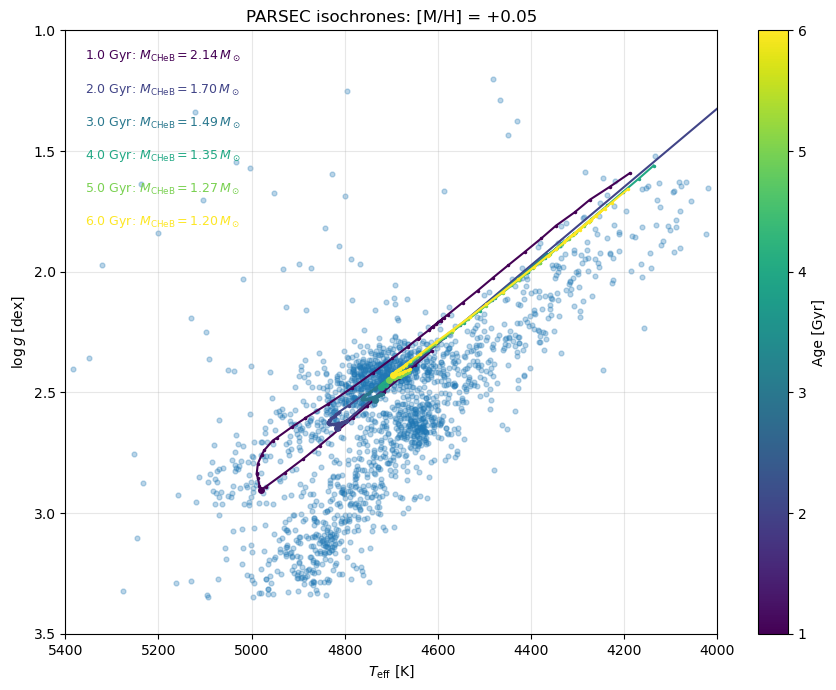

In [ ]:
# Plot Kiel diagram
fig, ax = plt.subplots(figsize=(9, 7))

cmap = plt.cm.viridis
norm = plt.Normalize(min(ages)/1e9, max(ages)/1e9)



for age, iso in isochrones.items():

    Teff = 10**iso["logTe"]
    ax.plot(
        Teff[150:200],
        iso["logg"][150:200],
        marker=".",
        markersize=3,
        linestyle="-",
        color=cmap(norm(age/1e9)),
        label=f"{age/1e9:.1f} Gyr"
    )

    
    idx = iso.iloc[150:200]["logg"].idxmax()
    ax.plot(Teff.loc[idx], iso.loc[idx, "logg"], marker="o", markersize=4, color=cmap(norm(age / 1e9)))

    CHeB_mass = iso.loc[idx, "Mini"]
    age_index = np.argmin(np.abs(ages - age))

    CHeB_mass = iso.loc[idx, "Mini"]
    CHeB_label = iso.loc[idx, "label"]
    age_index = np.argmin(np.abs(ages - age))

    print(f"{age / 1e9:.1f} Gyr: CHeB mass = {CHeB_mass:.2f} M☉")

    
#plot the observed data

load_path = "../../data/my_data/stars_bin8.csv"
stars_bin8 = pd.read_csv(load_path)
ax.scatter(stars_bin8['Teff'], stars_bin8['logg_scaling'], s=12, alpha=0.3) 



# Colorbar
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, ax=ax)
cbar.set_label("Age [Gyr]")

#plot the observed data

# Labels
ax.set_xlabel(r"$T_{\rm eff}\ [\mathrm{K}]$")
ax.set_ylabel(r"$\log g\ [\mathrm{dex}]$")
ax.set_title(rf"PARSEC isochrones: [M/H] = {metallicity:+.2f}")

ax.set_xlim(5400, 4000)
ax.set_ylim(3.5,1.0)

ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

! phase transition
From here I can conclude that the phase transition between RC and sRC is between 1.5 and 1.8 Gyrs when the maximum logg of the CHeB phase goes increases very very fast. The same phase transition can be indentified in mass, between 1.76 and 1.90 solar masses. So when binning in mass for solar metallicity one edge must fall in between this range (1.76 to 1.90 solar masses), for example taking the average of this range we can choose 1.85 solar masses.

! bin errors
lets say we take the bin in mass [1.5, 1.4] a change in mass of 0.1, we can identify the respetively CHeB region in the diagram and check how much logg and teff change. For feh= 0.0 the logg changes between (2.50, 2.55) a difference of 0.05 dex and teff changes between (4772 ,4762) a difference of around 100 K

I cannot use it for RGB bump--> no phase transition
Could i use it for detecting where changes from RC to HB --> nice but useless for the purpose of separating CHeB from RGB

In [6]:
"""# Plot only one track signaling the RC region (Kiel diagram)
fig, ax = plt.subplots(figsize=(9, 7))

ax.plot(
    iso["Teff"],
    iso["logg"],
    marker=".",
    linestyle="-"
)


print(len(iso["Teff"]))
ax.plot(
    iso["Teff"][161:170],
    iso["logg"][161:170],
    marker=".",
    linestyle="-",
    color="orange"
)



ax.set_xlabel(r"$T_{\rm eff}\ [\mathrm{K}]$")
ax.set_ylabel(r"$\log g\ [\mathrm{dex}]$")
ax.set_xlim(5400, 4000)
ax.set_ylim(3.5,1.0)
ax.set_title(
    rf"PARSEC: Age = {age/1e9:.1f} Gyr, [M/H] = {metallicity:+.2f}"
)


ax.axhline(y=2.65, color="gray", linestyle="--", alpha=0.5, label="sRC (logg=2.9)")



ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()
"""

'# Plot only one track signaling the RC region (Kiel diagram)\nfig, ax = plt.subplots(figsize=(9, 7))\n\nax.plot(\n    iso["Teff"],\n    iso["logg"],\n    marker=".",\n    linestyle="-"\n)\n\n\nprint(len(iso["Teff"]))\nax.plot(\n    iso["Teff"][161:170],\n    iso["logg"][161:170],\n    marker=".",\n    linestyle="-",\n    color="orange"\n)\n\n\n\nax.set_xlabel(r"$T_{\rm eff}\\ [\\mathrm{K}]$")\nax.set_ylabel(r"$\\log g\\ [\\mathrm{dex}]$")\nax.set_xlim(5400, 4000)\nax.set_ylim(3.5,1.0)\nax.set_title(\n    rf"PARSEC: Age = {age/1e9:.1f} Gyr, [M/H] = {metallicity:+.2f}"\n)\n\n\nax.axhline(y=2.65, color="gray", linestyle="--", alpha=0.5, label="sRC (logg=2.9)")\n\n\n\nax.grid(alpha=0.3)\nfig.tight_layout()\nplt.show()\n'

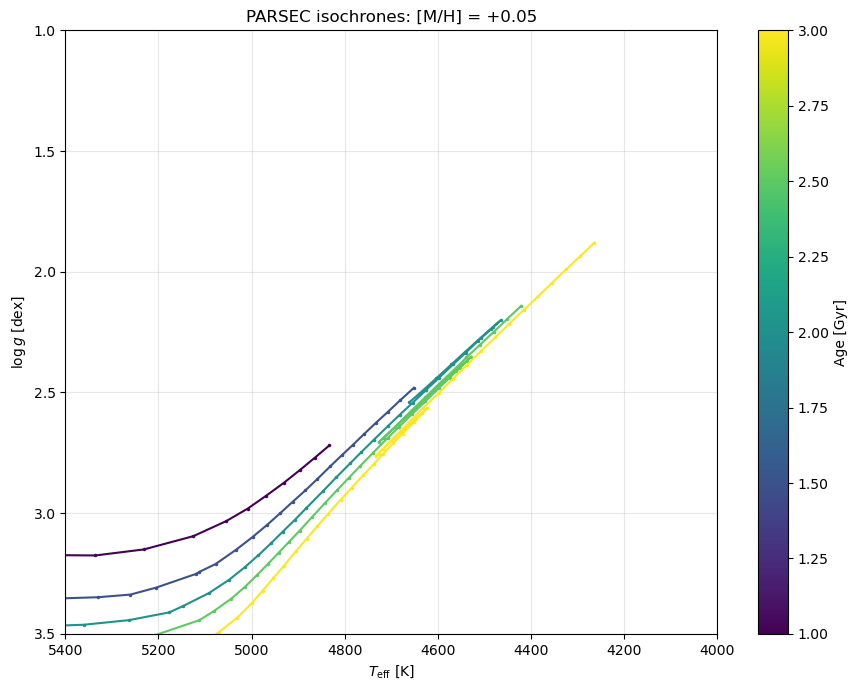

In [7]:
# Plot Kiel diagram
fig, ax = plt.subplots(figsize=(9, 7))

cmap = plt.cm.viridis
norm = plt.Normalize(min(ages)/1e9, max(ages)/1e9)

for age, iso in isochrones.items():

    Teff = 10**iso["logTe"]
    
    ax.plot(
        Teff[10:120],
        iso["logg"][10:120],
        marker=".",
        markersize=3,
        linestyle="-",
        color=cmap(norm(age/1e9)),
        label=f"{age/1e9:.1f} Gyr"
    )

"""    
    idx = iso.iloc[10:100]["logg"].idxmax()
    ax.plot(Teff.loc[idx], iso.loc[idx, "logg"], marker="o", markersize=4, color=cmap(norm(age / 1e9)))

    CHeB_mass = iso.loc[idx, "Mini"]
    age_index = np.argmin(np.abs(ages - age))

    CHeB_mass = iso.loc[idx, "Mini"]
    CHeB_label = iso.loc[idx, "label"]
    age_index = np.argmin(np.abs(ages - age))"""

"""    ax.text(
        0.03,
        0.97 - age_index * 0.055,
        (
            rf"{age / 1e9:.1f} Gyr: $M_{{\rm CHeB}}={CHeB_mass:.2f}\,M_\odot$"
            #rf"  (label={CHeB_label}, "
            #rf"Teff={Teff.loc[idx]:.0f} K, logg={iso.loc[idx, 'logg']:.2f})"
        ),
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=9,
        color=cmap(norm(age / 1e9))
    )"""

# Colorbar
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, ax=ax)
cbar.set_label("Age [Gyr]")

# Labels
ax.set_xlabel(r"$T_{\rm eff}\ [\mathrm{K}]$")
ax.set_ylabel(r"$\log g\ [\mathrm{dex}]$")
ax.set_title(rf"PARSEC isochrones: [M/H] = {metallicity:+.2f}")

ax.set_xlim(5400, 4000)
ax.set_ylim(3.5,1.0)

ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

In [8]:
print(iso.columns.tolist())

# Original PARSEC header/comments
print(iso.attrs.get("comment"))  #I have to add the reference to the PARSEC paper in the final version of the notebook/thesis

['Zini', 'MH', 'logAge', 'Mini', 'int_IMF', 'Mass', 'logL', 'logTe', 'logg', 'label', 'McoreTP', 'C_O', 'period0', 'period1', 'period2', 'period3', 'period4', 'pmode', 'Mloss', 'tau1m', 'X', 'Y', 'Xc', 'Xn', 'Xo', 'Cexcess', 'Z', 'mbolmag', 'Gmag', 'G_BPmag', 'G_RPmag', 'Teff', 'L']
File generated by CMD 3.9 (http://stev.oapd.inaf.it/cmd) on Thu Nov  5 13:15:30 UTC 2026
isochrones based on PARSEC release v1.2S +  COLIBRI S_37 + S_35 + PR16
Basic references: Bressan et al. (2012), MNRAS, 427, 127 + Chen et al. (2014, 2015), MNRAS, 444, 2525 + MNRAS, 452, 1068 + Tang et al. (2014), MNRAS, 445, 4287 + Marigo et al. (2017), ApJ, 835, 77 + Pastorelli al. (2019), MNRAS, 485, 5666 + Pastorelli al. (2020), MNRAS, in press
Thermal pulse cycles included
On RGB, assumed Reimers mass loss with efficiency eta=0.2
LPV periods and growth rates added cf. Trabucchi et al. (2019)
but fundamental-mode LPV periods are from Trabucchi et al. (2021)
Photometric system: Gaia EDR3 (all Vegamags, Gaia passbands

### Mass for the oldest RC star 

In [9]:

# Output directory
output_dir = pathlib.Path("parsec_isochrones")
output_dir.mkdir(exist_ok=True)

# Parameters
metallicity = -0.1 # Extreme negative metallicity
ages = np.arange(13, 13, 0) * 1e9  # MW age

isochrones={}


for age in ages:

    print(f"Querying PARSEC: age = {age/1e9:.1f} Gyr")

    iso = ezpadova.get_isochrones(
        age_yr=(age, age, 0),
        MH=(metallicity, metallicity, 0),
        photsys_file="gaiaEDR3"
    )

    isochrones[age] = iso

    # Save
    filename = output_dir / f"isochrone_age_{age/1e9:.1f}Gyr.csv"
    iso.to_csv(filename, index=False)

    print(f"Saved {filename} | Points: {len(iso)}")

ZeroDivisionError: division by zero

In [ ]:
# Plot Kiel diagram
fig, ax = plt.subplots(figsize=(9, 7))

cmap = plt.cm.viridis
norm = plt.Normalize(min(ages)/1e9, max(ages)/1e9)

for age, iso in isochrones.items():

    Teff = 10**iso["logTe"]
    ax.plot(
        Teff,
        iso["logg"],
        marker=".",
        markersize=3,
        linestyle="-",
        color=cmap(norm(age/1e9)),
        label=f"{age/1e9:.1f} Gyr"
    )

    
    idx = iso.iloc[150:200]["logg"].idxmax()
    ax.plot(Teff.loc[idx], iso.loc[idx, "logg"], marker="o", markersize=4, color=cmap(norm(age / 1e9)))

    CHeB_mass = iso.loc[idx, "Mini"]
    age_index = np.argmin(np.abs(ages - age))

    CHeB_mass = iso.loc[idx, "Mini"]
    CHeB_label = iso.loc[idx, "label"]
    age_index = np.argmin(np.abs(ages - age))

    ax.text(
        0.03,
        0.97 - age_index * 0.055,
        (
            rf"{age / 1e9:.1f} Gyr: $M_{{\rm CHeB}}={CHeB_mass:.2f}\,M_\odot$"
            #rf"  (label={CHeB_label}, "
            #rf"Teff={Teff.loc[idx]:.0f} K, logg={iso.loc[idx, 'logg']:.2f})"
        ),
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=9,
        color=cmap(norm(age / 1e9))
    )

# Colorbar
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, ax=ax)
cbar.set_label("Age [Gyr]")

# Labels
ax.set_xlabel(r"$T_{\rm eff}\ [\mathrm{K}]$")
ax.set_ylabel(r"$\log g\ [\mathrm{dex}]$")
ax.set_title(rf"PARSEC isochrones: [M/H] = {metallicity:+.2f}")

ax.set_xlim(5400, 4000)
ax.set_ylim(3.5,1.0)

ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## MIST

In [ ]:
from pathlib import Path
from isochrones.mist import MISTEvolutionTrackGrid


# ============================================================
# 1. PARAMETERS
# ============================================================

output_dir = Path("MIST_tracks")
output_dir.mkdir(exist_ok=True)

Masses = np.round(np.arange(1.5, 2.51, 0.25), 2)

# Available MIST v1.2 metallicities
metallicities = [0.0]

# MIST configuration
version = "1.2"
vvcrit = 0.0  # Non-rotating models
afe = 0.0     # Solar-scaled abundances


# ============================================================
# 2. LOAD MIST TRACK GRID
# ============================================================

print("Loading MIST evolutionary tracks...")

track_grid = MISTEvolutionTrackGrid(
    version=version,
    vvcrit=vvcrit,
    afe=afe
)

# Retrieve the grid as a DataFrame
tracks_all = track_grid.df.reset_index()

print("Available columns:")
print(tracks_all.columns.tolist())

Holoviews not imported. Some visualizations will not be available.
PyMultiNest not imported.  MultiNest fits will not work.


Loading MIST evolutionary tracks...


interpolating missing values in evolution tracks (feh=-3.5)':   0%|          | 0/196 [00:00<?, ?it/s]/home/juan-idarraga/packages/miniconda3/envs/thesis/lib/python3.10/site-packages/isochrones/mist/models.py:382: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value 'True' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  new_data.loc[:, "interpolated"] = True
interpolating missing values in evolution tracks (feh=-3.5)':  35%|███▌      | 69/196 [00:00<00:00, 508.35it/s]/home/juan-idarraga/packages/miniconda3/envs/thesis/lib/python3.10/site-packages/isochrones/mist/models.py:382: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value 'True' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  new_data.loc[:, "interpolated"] = True
/home/juan-idarraga/packages/miniconda3/envs/thesis/lib/

IndexError: index 196 is out of bounds for axis 0 with size 196

In [ ]:

# ============================================================
# 3. SELECT TRACKS
# ============================================================

tracks = {}

for feh in metallicities:

    print(f"\nProcessing [Fe/H] = {feh:+.2f}")

    # Select metallicity
    feh_data = tracks_all[
        np.isclose(tracks_all["initial_feh"], feh)
    ].copy()

    if feh_data.empty:
        print(f"No tracks found for [Fe/H] = {feh}")
        continue

    available_masses = np.sort(
        feh_data["initial_mass"].unique()
    )

    tracks[feh] = {}

    for Mini in Masses:

        # Find closest available initial mass
        closest_mass = available_masses[
            np.argmin(np.abs(available_masses - Mini))
        ]

        # Select individual evolutionary track
        track = feh_data[
            np.isclose(feh_data["initial_mass"], closest_mass)
        ].copy()

        tracks[feh][Mini] = track

        # Save track
        filename = (
            output_dir /
            f"track_M{closest_mass:.2f}_FeH_{feh:+.2f}.csv"
        )

        track.to_csv(filename, index=False)

        print(
            f"Requested: {Mini:.2f} Msun | "
            f"Available: {closest_mass:.4f} Msun | "
            f"Points: {len(track)}"
        )

In [ ]:
# ============================================================
# 4. PLOT KIEL DIAGRAM
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 6),
    sharex=True,
    sharey=True
)

for ax, feh in zip(axes, metallicities):

    for Mini, track in tracks[feh].items():

        ax.plot(
            track["Teff"],
            track["logg"],
            label=f"{Mini:.1f} Msun"
        )

    ax.set_title(rf"[Fe/H] = {feh:+.2f}")
    ax.set_xlabel(r"$T_{\rm eff}\ [K]$")

    ax.invert_xaxis()
    ax.invert_yaxis()

    ax.grid(alpha=0.3)

axes[0].set_ylabel(r"$\log g\ [dex]$")

axes[-1].legend(
    fontsize=8,
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

fig.suptitle(
    "MIST evolutionary tracks",
    fontsize=15
)

fig.tight_layout()
plt.show()
